# 07: Results overview, the whole project on one page

**Question.** Does a fatigue model still work on people it has never seen?

**Why it matters.** EEG fatigue detection has a generalisation problem: across the published literature, models that score very highly on the people they were trained on collapse toward chance on unseen people. This project measured that collapse under leakage-controlled evaluation, on two datasets, with two model families and two label philosophies, with the decision rules written down before the results were interpreted.

This notebook is the map. Every number below is rebuilt from the stored summary tables in `results/tables/`, the figures are the ones in `results/figures/`, and the full reasoning for every step is in `track.md` and the write-ups in `docs/`. The chapter notebooks walk through each phase: 01 data inspection, 02 the Week 2 baseline, 03 DROZY, 04 the CNN on Colab, 05 RQ4 and the replication, 06 RQ3.

## 0. Setup

In [1]:
# Setup. The pipeline in src/ is the engine; this notebook is a front door
# to it. Here I find the repository root, put the frozen modules and the
# pinned libraries on the path, and patch one NumPy rename.
import sys
from pathlib import Path

import numpy as np
import pandas as pd

if not hasattr(np, "trapz"):
    # NumPy 2.x renamed trapz to trapezoid. The frozen band-power module
    # still calls np.trapz, so I alias it here instead of editing frozen code.
    np.trapz = np.trapezoid


def find_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "src" / "features" / "bandpower.py").exists():
            return cand
    raise FileNotFoundError("repository root not found above the working directory")


ROOT = find_root()
for extra in (str(ROOT), str(Path.home() / "workspace" / ".pylibs")):
    if Path(extra).exists() and extra not in sys.path:
        sys.path.insert(0, extra)

TAB = ROOT / "results" / "tables"
FIG = ROOT / "results" / "figures"
PROC = ROOT / "data" / "processed"
pd.set_option("display.width", 120)
print("repository root:", ROOT)

repository root: /home/hatch/workspace/thesis-fatigue


## 1. The headline table, rebuilt from the stored tables

In [2]:
rows = []

gap = pd.read_csv(TAB / "rq1_generalisation_gap.csv").set_index("model")
ceil = pd.read_csv(TAB / "diagnostics_within_session_ceiling.csv")
rows.append(("RQ1", "same-session estimate (baseline)",
             f"{ceil.balanced_accuracy.mean():.3f}",
             "position-confounded upper bound, not decoding"))
rows.append(("RQ1", "honest within-subject (baseline / CNN)",
             f"{gap.loc['band-power baseline', 'within_ba']:.3f} / {gap.loc['1D-CNN (EEGNet)', 'within_ba']:.3f}",
             "at chance"))
rows.append(("RQ1", "leave-one-participant-out (baseline / CNN)",
             f"{gap.loc['band-power baseline', 'lopo_ba']:.3f} / {gap.loc['1D-CNN (EEGNet)', 'lopo_ba']:.3f}",
             "at chance"))

con = pd.read_csv(TAB / "cnn_loso_rq2_contrast_canonical806.csv")
con = con[con.participant != "MEAN_DIFF"]
rows.append(("RQ2", "CNN minus baseline, identical windows (mean paired difference)",
             f"{con['diff'].mean():+.3f}",
             "no evidence of a CNN advantage"))

dz = pd.read_csv(TAB / "drozy_lopo_aggregate.csv").set_index("combo")
rows.append(("DROZY", "KSS labels, LOPO",
             f"{dz.loc['kss_all', 'balanced_accuracy']:.3f}",
             "decodable across participants (p = 0.005)"))
rows.append(("DROZY", "RT labels, same recordings, LOPO",
             f"{dz.loc['rt_all', 'balanced_accuracy']:.3f}",
             "not decodable (p = 0.726); smaller effects not excluded"))

rq4 = pd.read_csv(TAB / "rq4_aggregates.csv")
v = rq4[(rq4.arm == "all36") & (rq4.protocol == "loso")].balanced_accuracy.iloc[0]
rows.append(("RQ4", "block-phase labels, LOPO (primary labels: 0.508)",
             f"{v:.3f}",
             "the subjective filter does not matter"))
proto = pd.read_csv(TAB / "rq4_replication_proto_summary.csv")
plr = proto[(proto.model == "lr") & (proto.split == "chronological")
            & (proto.subset == "all")].balanced_accuracy.iloc[0]
rows.append(("RQ4", "preliminary setup rebuilt exactly (LR)",
             f"{plr:.3f}",
             "reproduces, and identifies the session, not fatigue"))

arms = pd.read_csv(TAB / "rq3_arm_summary.csv")


def arm_ba(a):
    r = arms[(arms.pool == "keepall") & (arms.protocol == "lopo") & (arms.arm == a)]
    return r.balanced_accuracy_mean.iloc[0]


rows.append(("RQ3", "peripheral vs indicators-only, LOPO",
             f"{arm_ba('peripheral'):.3f} vs {arm_ba('indicators'):.3f}",
             "protocol contrast recovered; fatigue not separated from exercise"))

headlines = pd.DataFrame(rows, columns=["question", "result", "balanced_accuracy", "locked_reading"])
headlines

,question,result,balanced_accuracy,locked_reading
0,RQ1,same-session estimate (baseline),0.744,"position-confounded upper bound, not decoding"
1,RQ1,honest within-subject (baseline / CNN),0.484 / 0.493,at chance
2,RQ1,leave-one-participant-out (baseline / CNN),0.508 / 0.493,at chance
3,RQ2,"CNN minus baseline, identical windows (mean pa...",+0.005,no evidence of a CNN advantage
4,DROZY,"KSS labels, LOPO",0.602,decodable across participants (p = 0.005)
5,DROZY,"RT labels, same recordings, LOPO",0.482,not decodable (p = 0.726); smaller effects not...
6,RQ4,"block-phase labels, LOPO (primary labels: 0.508)",0.516,the subjective filter does not matter
7,RQ4,preliminary setup rebuilt exactly (LR),1.000,"reproduces, and identifies the session, not fa..."
8,RQ3,"peripheral vs indicators-only, LOPO",0.741 vs 0.539,protocol contrast recovered; fatigue not separ...


## 2. The locked claims

These are the sentences the results are reported under, agreed before anything was called final:

- **RQ1** is reported as three tiers, not a gap: same-session 0.744 (position-confounded), honest within-subject at chance, LOPO at chance. With both honest tiers at the floor, the pre-registered within-minus-LOPO gap is uninformative.
- **RQ2:** no evidence that either model exceeds chance on unseen participants on FatigueSet, and no evidence of a CNN advantage, scoped to the frozen EEGNet configuration. The CNN null is weak evidence: 16 of 55 fits were near-constant, scoring exactly 0.5, so the result is a null for this configuration and does not bound what a differently trained network could do.
- **DROZY:** KSS-extreme labels were decodable across participants; RT-extreme labels from the same recordings were not; this contrast is not isolated from session order and rests on a small disagreeing subset. The positive control passed its gate and priced the RT null: reliable detection of injected shifts at dose 0.5 and above, smaller changes not ruled out.
- **RQ4:** The preliminary result reproduces in its own configuration, but there the fatigued class coincides almost perfectly with a session-wide amplitude regime that fails the pre-declared quality criterion (mask-retained 97.1% vs 2.5%). The score therefore identifies the session and cannot be read as evidence of fatigue decoding. The available data do not separate placement or contact differences from state-correlated physiology or behaviour.
- **RQ3:** peripheral features recover the protocol-defined M1/M3 contrast across participants, and the design cannot separate fatigue from exercise-related physiology.

## 3. The figures

RQ1 tiers, and RQ2 per participant:

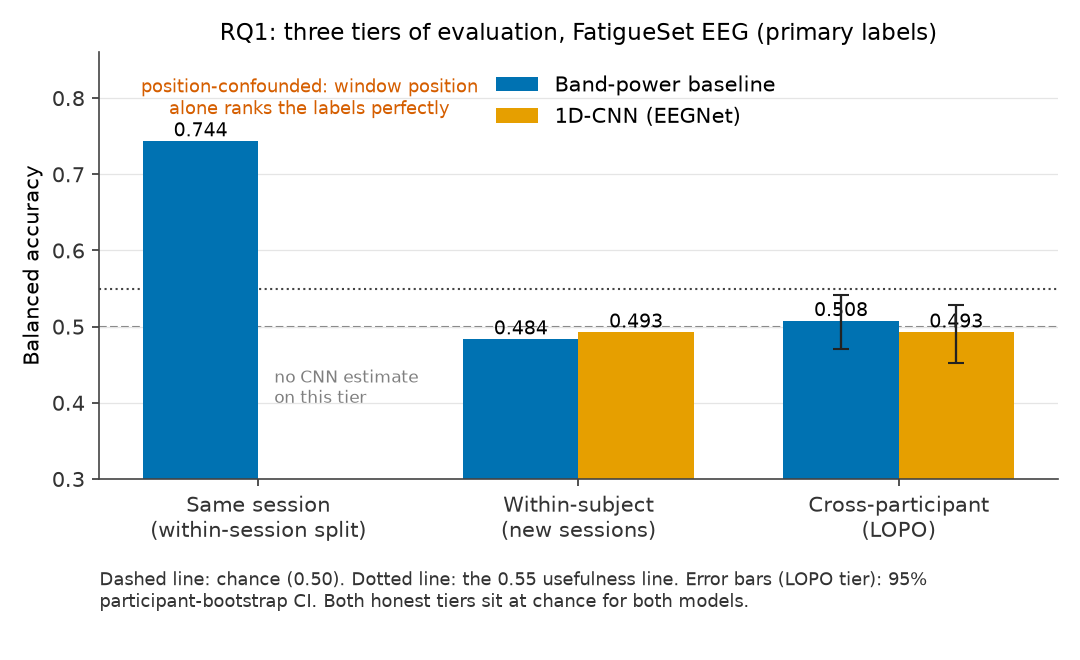

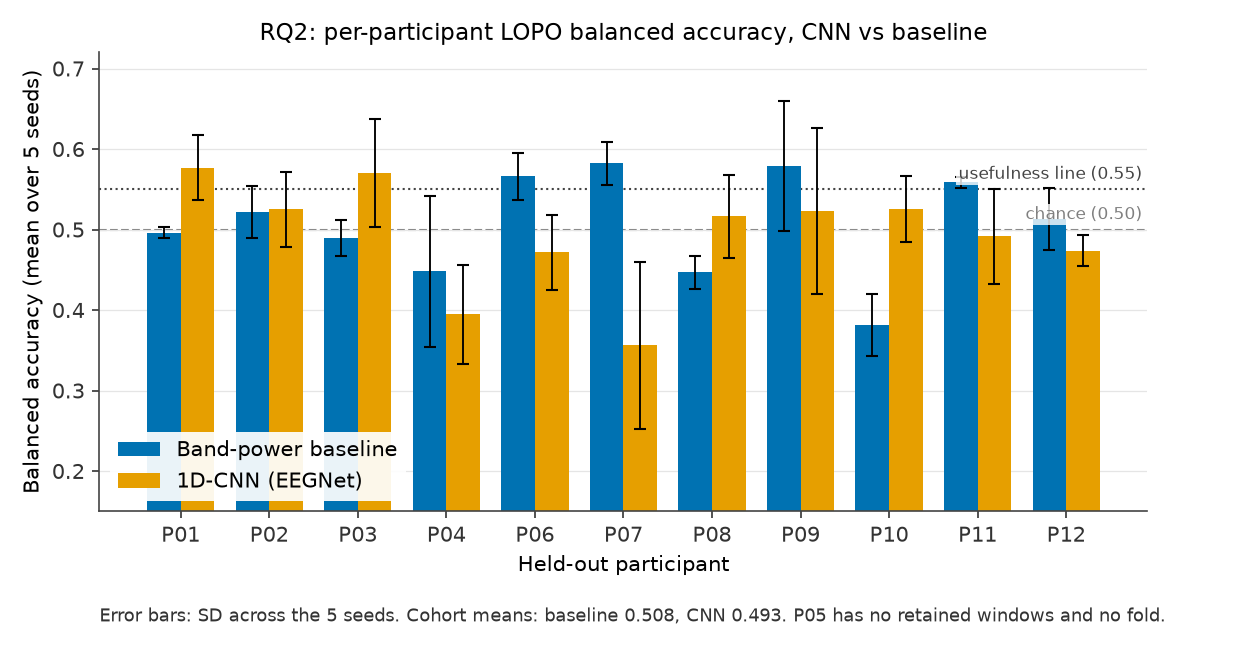

In [3]:
from IPython.display import Image, display

for name in ["fig_rq1_tiers.png", "fig_rq2_perparticipant.png"]:
    display(Image(filename=str(FIG / name)))

The DROZY dissociation, and the RQ4 ladder:

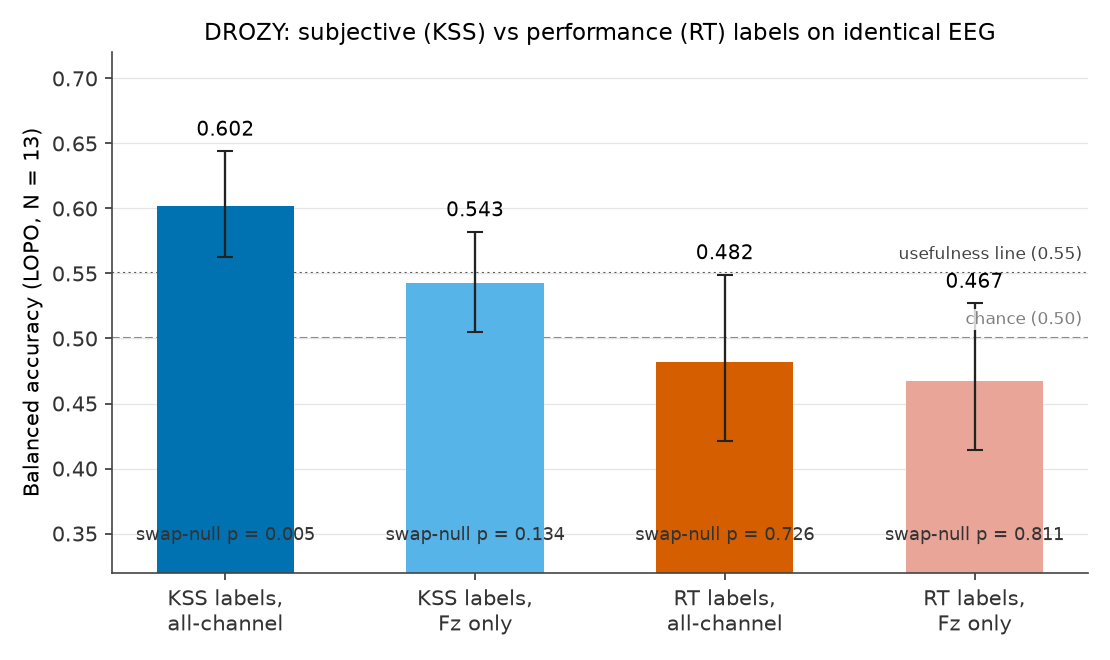

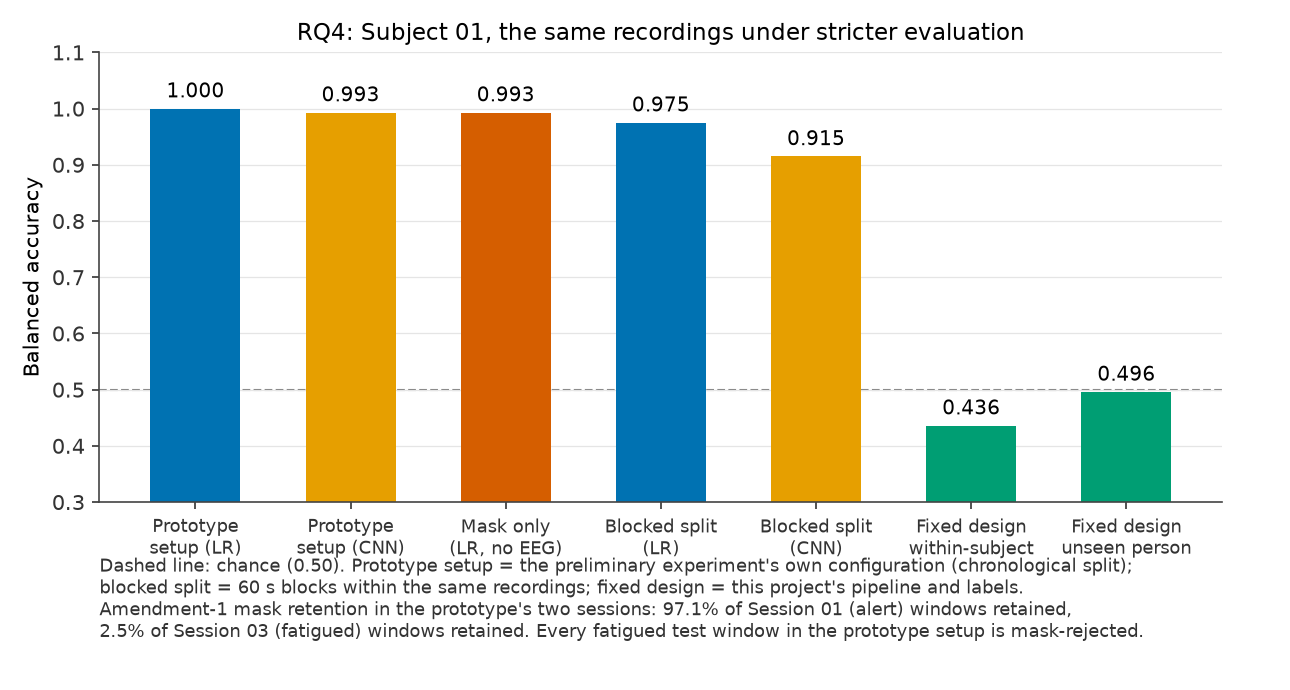

In [4]:
for name in ["fig_drozy_dissociation.png", "fig_rq4_ladder.png"]:
    display(Image(filename=str(FIG / name)))

RQ3, the arms and the heart-rate check:

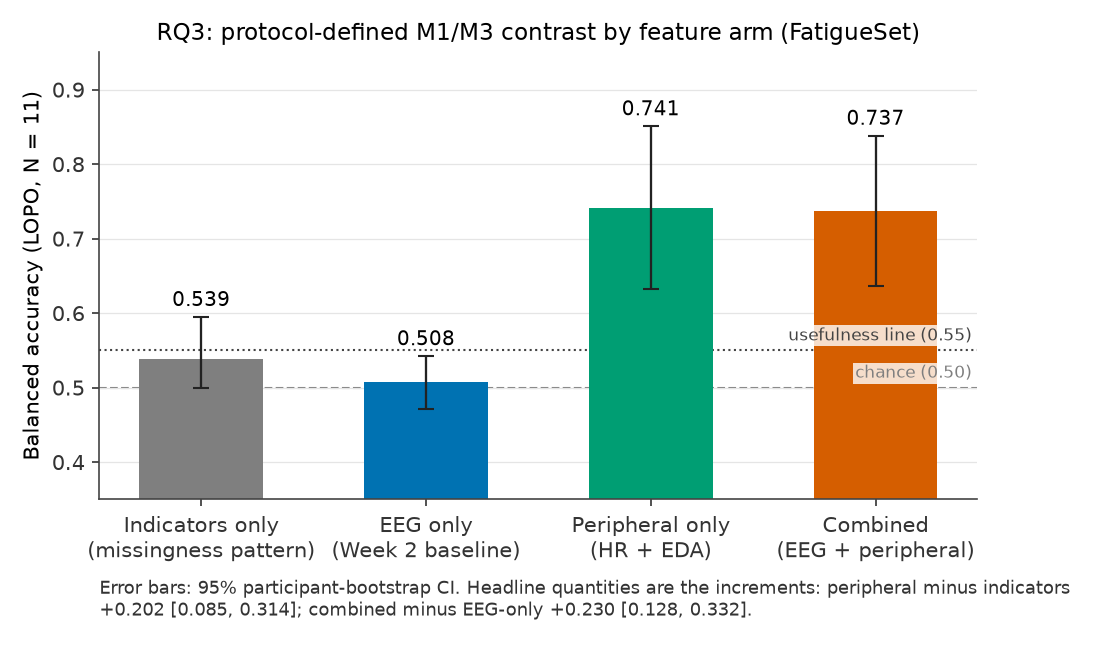

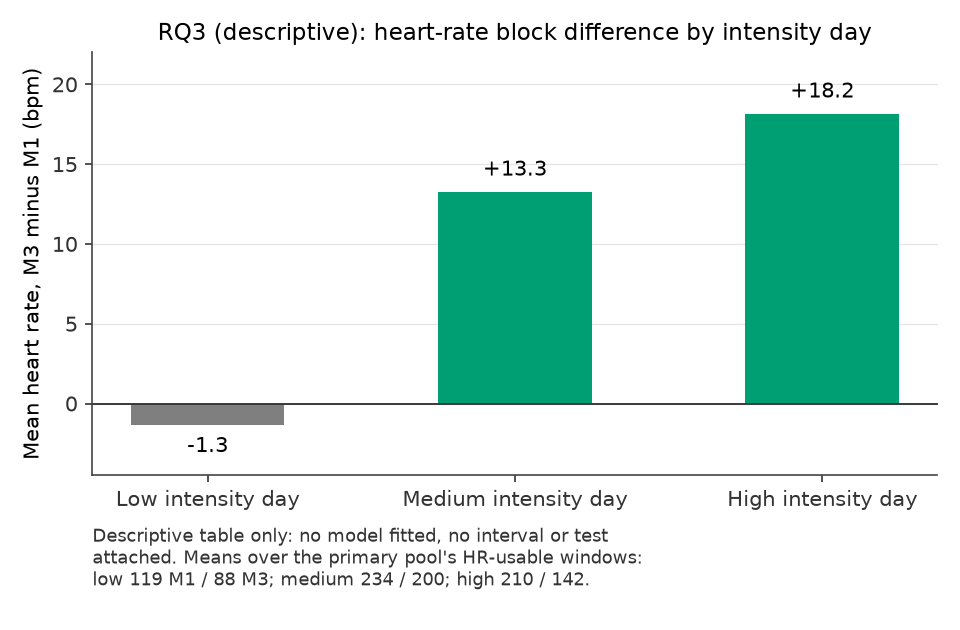

In [5]:
for name in ["fig_rq3_arms.png", "fig_rq3_hr_intensity.png"]:
    display(Image(filename=str(FIG / name)))

## 4. Where everything lives

- `track.md`: the complete build log. Every step, every parameter, every error, every result, and the reason for each decision.
- `docs/label_rules.md` and `docs/decision_table_lock.md`: the label rules and the claim rules, locked before results were interpreted.
- `docs/week2_diagnostics.md`: the Week 2 diagnostics behind notebook 02.
- `docs/cnn_loso_results.md`: the RQ2 comparison in full, including the degeneracy analysis.
- `docs/drozy_results.md` and `docs/drozy_positive_control.md`: the DROZY result and its control, behind notebook 03.
- `docs/rq4_session_labels.md`: RQ4 and the replication, behind notebook 05.
- `docs/rq3_results.md`: RQ3 in full, behind notebook 06.
- `docs/writing_pack/results_summary.md`: every headline number with its locked wording, gathered for the write-up.
- `experiments/runs/`: one folder per run, with its config, metrics and notes. `results/tables/`: the summary tables these notebooks read.

## 5. Status

All four research questions are answered, both datasets are analysed, and the positive controls, diagnostics and sensitivity checks are done and written up. What remains is the writing.